# Step 3: annotate the cells with CellTypist

Load the combined count matrix produced by nf-core/scrnaseq (registered in LaminDB by nf-lamin),
annotate immune cell types with CellTypist, and save the result as a new artifact.

In [35]:
import lamindb as ln
import scanpy as sc
import celltypist
from celltypist import models

ln.track("MKKPcGfush7g", path = "3_annotate.ipynb")

→ loaded Transform('MKKPcGfush7g0001', key='3_annotate.ipynb'), re-started Run('IFTg85ng1wdxmam4') at 2026-07-24 07:38:30 UTC
→ notebook imports: celltypist==1.7.1 lamindb-core==2.8.1 scanpy==1.12.2


Look up artifact

In [36]:
artifact = ln.Artifact.get("aqOOFyumixTtQNOs")
artifact

Artifact(uid='aqOOFyumixTtQNOs0000', key='scrnaseq_showcase/run_20260723_202024/simpleaf/mtx_conversions/combined_cellbender_filter_matrix.h5ad', description='Output artifact for run 11677', suffix='.h5ad', kind='dataset', otype='AnnData', size=481441072, hash='uw05yCdZMEFb75_kzINYeg', n_files=None, n_observations=None, extra_data=None, branch_id=1, created_on_id=1, space_id=1, storage_id=61, run_id=11677, schema_id=None, created_by_id=54, created_at=2026-07-23 18:35:19 UTC, is_locked=False, version_tag=None, is_latest=True)

Load artifact

In [37]:
adata = artifact.load()
adata

AnnData object with n_obs × n_vars = 8838 × 62754
    obs: 'barcodes', 'corrected_reads', 'mapped_reads', 'deduplicated_reads', 'mapping_rate', 'dedup_rate', 'mean_by_max', 'num_expressed', 'num_genes_over_mean', 'sample', 'fastq_1', 'fastq_2', 'expected_cells'
    var: 'gene_id', 'gene_symbol', 'gene_versions'
    varm: 'ambiguous', 'spliced', 'unspliced'
    layers: 'ambiguous', 'spliced', 'unspliced'

Prepare the AnnData for celltypist

In [38]:
adata.var_names = adata.var["gene_symbol"].astype(str)
adata.var_names_make_unique()
adata.var.index.name = None

sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

Run celltypist

In [39]:
models.download_models(model="Immune_All_Low.pkl")
predictions = celltypist.annotate(adata, model="Immune_All_Low.pkl", majority_voting=True)
adata.obs["cell_type"] = predictions.predicted_labels["majority_voting"].values
adata.obs["cell_type"].value_counts()

📂 Storing models in /home/rcannood/.celltypist/data/models
💾 Total models to download: 1
⏩ Skipping [1/1]: Immune_All_Low.pkl (file exists)
🔬 Input data has 8838 cells and 62754 genes
🔗 Matching reference genes in the model
🧬 6104 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!
👀 Can not detect a neighborhood graph, will construct one before the over-clustering
⛓️ Over-clustering input data with resolution set to 10
🗳️ Majority voting the predictions
✅ Majority voting done!


cell_type
Classical monocytes            2034
Tcm/Naive helper T cells       1874
Tcm/Naive cytotoxic T cells    1073
Naive B cells                   857
Tem/Trm cytotoxic T cells       622
Tem/Effector helper T cells     518
MAIT cells                      343
Memory B cells                  319
CD16+ NK cells                  293
Non-classical monocytes         211
Tem/Temra cytotoxic T cells     159
DC2                             134
Age-associated B cells          102
Regulatory T cells               99
pDC                              70
Megakaryocytes/platelets         61
NK cells                         35
HSC/MPP                          19
DC1                              15
Name: count, dtype: int64

Store AnnData

In [40]:
output = ln.Artifact.from_anndata(
    adata,
    key="annotated/pbmc8k.h5ad",
    description="CellTypist annotated PBMCs (Immune_All_Low)",
).save()

→ returning artifact with same hash: Artifact(uid='hsCH2XBEje5JOZzq0000', key='annotated/pbmc8k.h5ad', description='CellTypist annotated PBMCs (Immune_All_Low)', suffix='.h5ad', kind='dataset', otype='AnnData', size=484113278, hash='GZ62huQ9qpuYGNcb8Otoa4', n_files=None, n_observations=8838, extra_data=None, branch_id=1, created_on_id=1, space_id=1, storage_id=2, run_id=11708, schema_id=None, created_by_id=54, created_at=2026-07-24 07:22:08 UTC, is_locked=False, version_tag=None, is_latest=True); to track this artifact as an input, use: ln.Artifact.get()


In [41]:
ln.finish()

• please hit CTRL + s to save the notebook in your editor .... still waiting .....
....................! the notebook on disk wasn't saved within the last 10 sec
! cells [(0, None), (None, None), (None, 27), (29, None)] were not run consecutively
→ finished Run('IFTg85ng1wdxmam4') after 58s at 2026-07-24 07:39:29 UTC
! did *not* save source code and report -- to do so, run: lamin save 3_annotate.ipynb


View the full cross language lineage on LaminHub, or inline:

→ explore at: https://lamin.ai/laminlabs/lamindata/artifact/hsCH2XBEje5JOZzq0000


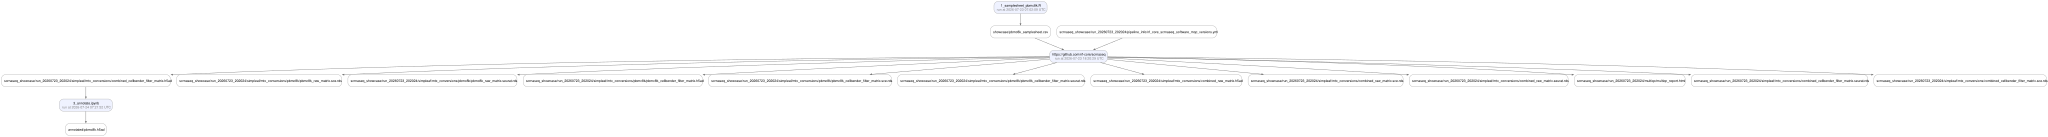

In [42]:
output.view_lineage()